## Import Libraries and Tools

In [1]:
import os
import numpy as np
import random
import matplotlib.pyplot as plt
import pandas as pd
import PIL.Image as Image
import PIL.ImageEnhance as ImageEnhance

# keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Flatten, Dropout
from tensorflow.keras.utils import load_img
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.applications import VGG16
from sklearn.utils import shuffle


I0000 00:00:1792950644.088793  128929 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792950644.095005  128929 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1792950644.677374  128929 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792950647.867730  128929 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.

## Local Dataset

In [8]:
%pip install kagglehub

  Attempting uninstall: certifi
    Found existing installation: certifi 2026.7.22
    Uninstalling certifi-2026.7.22:
      Successfully uninstalled certifi-2026.7.22
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [kagglehub]/4 [kagglesdk]

[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("masoudnickparvar/brain-tumor-mri-dataset")

print("Path to dataset files:", path)

Path to dataset files: /home/nishanta/.cache/kagglehub/datasets/masoudnickparvar/brain-tumor-mri-dataset/versions/2


In [3]:
train_dir = os.path.join(path, "Training")
test_dir = os.path.join(path, "Testing")


# Load and shuffle the train data
train_paths = []
train_labels = []
for label in os.listdir(train_dir):
    for image in os.listdir(os.path.join(train_dir, label)):
        train_paths.append(os.path.join(train_dir, label, image))
        train_labels.append(label)

train_paths, train_labels = shuffle(train_paths, train_labels)


# Load and shuffle the test data
test_paths = []
test_labels = []
for label in os.listdir(test_dir):
    for image in os.listdir(os.path.join(test_dir, label)):
        test_paths.append(os.path.join(test_dir, label, image))
        test_labels.append(label)

test_paths, test_labels = shuffle(test_paths, test_labels)


## Data Visualization

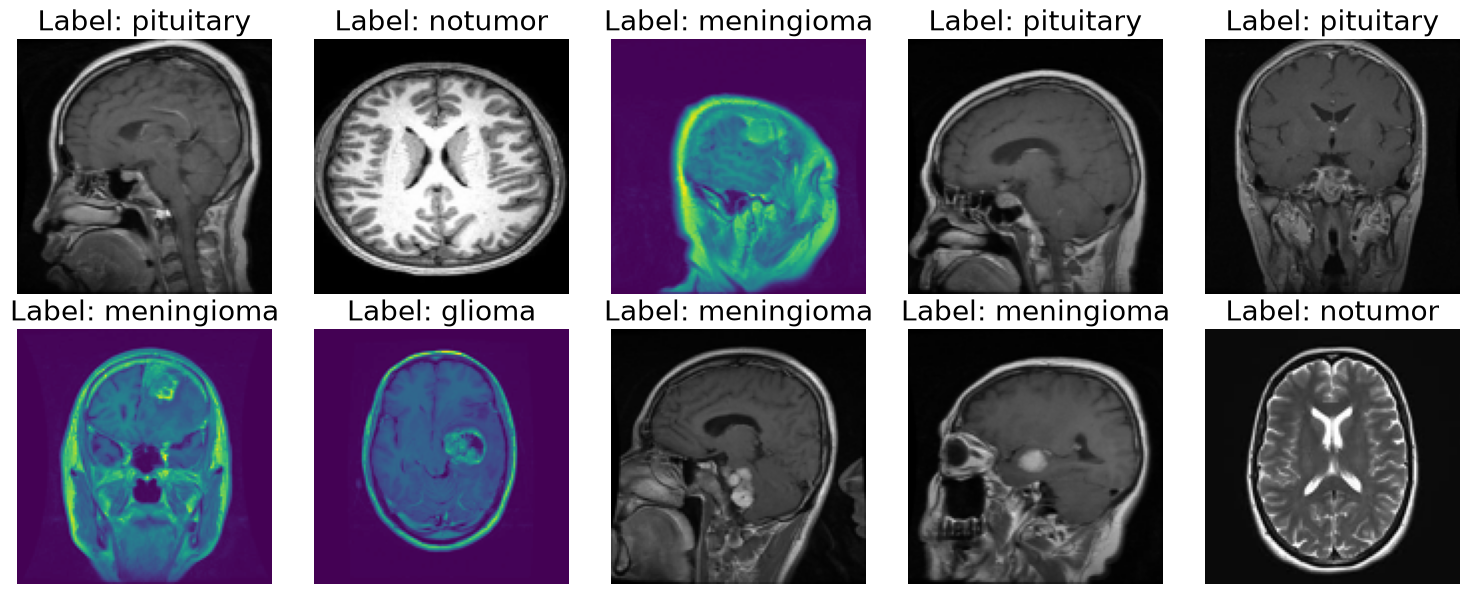

In [4]:
import random
import matplotlib.pyplot as plt

random_indices = random.sample(range(len(train_paths)),10)
random_indices

# Create a figure to display 10 images in 2 rows
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
axes = axes.ravel()

# Loop through the random indices and display the images
for i, idx in enumerate(random_indices):
    img_path = train_paths[idx]
    img = Image.open(img_path)
    img = img.resize((128, 128))  # Resize the image to 128x128

    axes[i].imshow(img)
    axes[i].axis('off')
    axes[i].set_title(f"Label: {train_labels[idx]}", fontsize=20)

plt.tight_layout()
plt.show()

## Image Preprocessing (Helper Function)

In [5]:
IMAGE_SIZE = 128
# Image augumentation function
def augment_image(image):
    image = Image.fromarray(np.uint8(image)) # convert to PIL image
    image = ImageEnhance.Brightness(image).enhance(random.uniform(0.8, 1.2))
    image = ImageEnhance.Contrast(image).enhance(random.uniform(0.8, 1.2))
    image = np.array(image)/255.0 # normalize the image
    return image

# Load images and apply augmentation
def open_images(paths):
    images = []
    for path in paths:
        img = load_img(path, target_size=(IMAGE_SIZE, IMAGE_SIZE))
        img = augment_image(img)
        images.append(img)
    return np.array(images)

# Encoder Labels (Convert label names into integers)
def encode_labels(labels):
    unique_labels = os.listdir(train_dir)
    encoded = [unique_labels.index(label) for label in labels]
    return encoded

# Data generator for batching 
def datagen(paths, labels, batch_size=12, epochs=1):
    for _ in range(epochs):
        for i in range(0, len(paths), batch_size):
            batch_paths = paths[i:i+batch_size]
            batch_images = open_images(batch_paths)
            batch_labels = labels[i:i+batch_size]
            batch_labels = np.asarray(encode_labels(batch_labels), dtype=np.int32)
            yield batch_images, batch_labels

## Model Architecture (VGG16)

In [14]:
IMAGE_SIZE = 128
base_model = VGG16(weights='imagenet', include_top=False, input_shape=(IMAGE_SIZE, IMAGE_SIZE, 3))

# Freeze all the layers of the VGG16 base model
for layer in base_model.layers:
    layer.trainable = False

# Set only the last few layers to be trainable
base_model.layers[-2].trainable = True
base_model.layers[-3].trainable = True
base_model.layers[-4].trainable = True

# Build the final model
model = Sequential()
model.add(Input(shape=(IMAGE_SIZE, IMAGE_SIZE, 3))) # Input Layer
model.add(base_model) # VGG16 Base Model
model.add(Flatten()) # Flatten the output of the base model
model.add(Dropout(0.3)) # Dropout layer for regularization

model.add(Dense(128, activation='relu')) # Fully connected layer with 128 units
model.add(Dropout(0.2))

model.add(Dense(len(os.listdir(train_dir)), activation='softmax')) # Output layer with softmax activation for multi-class classification


# Compile the model
model.compile(optimizer=Adam(learning_rate=0.0001), loss='sparse_categorical_crossentropy', metrics=['sparse_categorical_accuracy'])

# Paramerters for training
batch_size = 20
steps = (len(train_paths) + batch_size - 1) // batch_size
epochs = 5

# train the model
history = model.fit(
    datagen(train_paths, train_labels, batch_size=batch_size, epochs=epochs),
    steps_per_epoch=steps,
    epochs=epochs,
)

out = 'VGG16_model'
os.makedirs(out, exist_ok=True)
model.save(f'{out}/model.keras')
pd.DataFrame(history.history).to_csv(f'{out}/metrics.csv', index=False)



/home/nishanta/Projects/MRI_Detection/.venv/lib/python3.14/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a generator. The generator is expected to yield already-shuffled data.
  self.data_adapter = data_adapters.get_data_adapter(


Epoch 1/5


I0000 00:00:1792918610.398275  107564 generator_dataset_op.cc:213] Memory patch applied: M_TRIM_THRESHOLD=128 kb was set.


280/280 ━━━━━━━━━━━━━━━━━━━━ 302s 1s/step - loss: 0.4531 - sparse_categorical_accuracy: 0.8263
Epoch 2/5
280/280 ━━━━━━━━━━━━━━━━━━━━ 335s 1s/step - loss: 0.2316 - sparse_categorical_accuracy: 0.9116
Epoch 3/5
280/280 ━━━━━━━━━━━━━━━━━━━━ 322s 1s/step - loss: 0.1613 - sparse_categorical_accuracy: 0.9432
Epoch 4/5
280/280 ━━━━━━━━━━━━━━━━━━━━ 351s 1s/step - loss: 0.1117 - sparse_categorical_accuracy: 0.9566
Epoch 5/5
280/280 ━━━━━━━━━━━━━━━━━━━━ 369s 1s/step - loss: 0.0859 - sparse_categorical_accuracy: 0.9684


In [6]:
os.listdir(train_dir)
len(os.listdir(train_dir))

4

## Training Accuracy and Loss

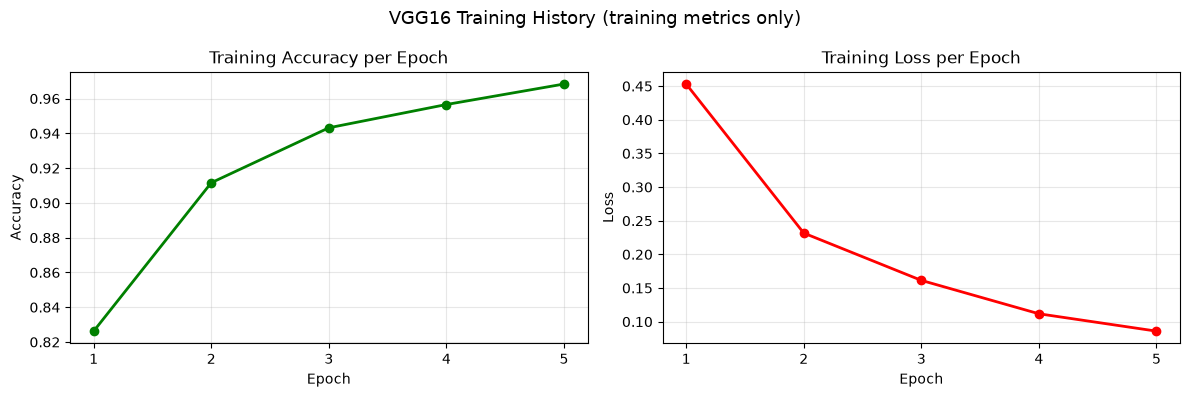

    loss  sparse_categorical_accuracy  epoch
0.453121                     0.826250      1
0.231637                     0.911607      2
0.161347                     0.943214      3
0.111717                     0.956607      4
0.085909                     0.968393      5


In [15]:
# Training accuracy and loss for the saved model, read from the metrics log
df = pd.read_csv("VGG16_model/metrics.csv")
epoch_numbers = np.arange(1, len(df) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(epoch_numbers, df['sparse_categorical_accuracy'], 'o-', color='green', linewidth=2)
axes[0].set_title('Training Accuracy per Epoch')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].set_xticks(epoch_numbers)
axes[0].grid(alpha=0.3)

axes[1].plot(epoch_numbers, df['loss'], 'o-', color='red', linewidth=2)
axes[1].set_title('Training Loss per Epoch')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].set_xticks(epoch_numbers)
axes[1].grid(alpha=0.3)

fig.suptitle('VGG16 Training History (training metrics only)', fontsize=13)
plt.tight_layout()
plt.show()

print(df.assign(epoch=epoch_numbers).to_string(index=False))

## Load the Trained Model and Run Test Predictions

In [16]:
from sklearn.preprocessing import label_binarize

# Class order must match the order used by encode_labels() during training,
# because it defines the meaning of each model output column.
class_names = os.listdir(train_dir)
model = tf.keras.models.load_model("VGG16_model/model.keras")


def load_test_images(paths):
    """Deterministic test preprocessing: resize + scale to [0,1].

    No random brightness/contrast augmentation here, so evaluation metrics
    are reproducible across runs.
    """
    images = []
    for path in paths:
        img = load_img(path, target_size=(IMAGE_SIZE, IMAGE_SIZE))
        images.append(np.asarray(img, dtype=np.float32) / 255.0)
    return np.array(images)


test_images = load_test_images(test_paths)
test_labels_encoded = np.array(encode_labels(test_labels))
test_predictions = model.predict(test_images, batch_size=32, verbose=0)
y_pred = np.argmax(test_predictions, axis=1)

print(f"Class order        : {class_names}")
print(f"Test images        : {test_images.shape}")
print(f"Prediction matrix  : {test_predictions.shape}")
print(f"Test accuracy      : {(y_pred == test_labels_encoded).mean():.4f}")

Class order        : ['meningioma', 'pituitary', 'notumor', 'glioma']
Test images        : (1600, 128, 128, 3)
Prediction matrix  : (1600, 4)
Test accuracy      : 0.9100


## Classification Report

In [17]:
from sklearn.metrics import classification_report

print("Classification Report\n")
print(classification_report(
    test_labels_encoded,
    y_pred,
    target_names=class_names,
    digits=4,
))

Classification Report
              precision    recall  f1-score   support
  meningioma     0.8068    0.9500    0.8726       400
   pituitary     0.9580    0.9700    0.9640       400
     notumor     0.9324    1.0000    0.9650       400
      glioma     0.9763    0.7200    0.8288       400
    accuracy                         0.9100      1600
   macro avg     0.9184    0.9100    0.9076      1600
weighted avg     0.9184    0.9100    0.9076      1600


## Confusion Matrix

Confusion Matrix (rows = true, columns = predicted)
[[380  10   3   7]
 [ 11 388   1   0]
 [  0   0 400   0]
 [ 80   7  25 288]]


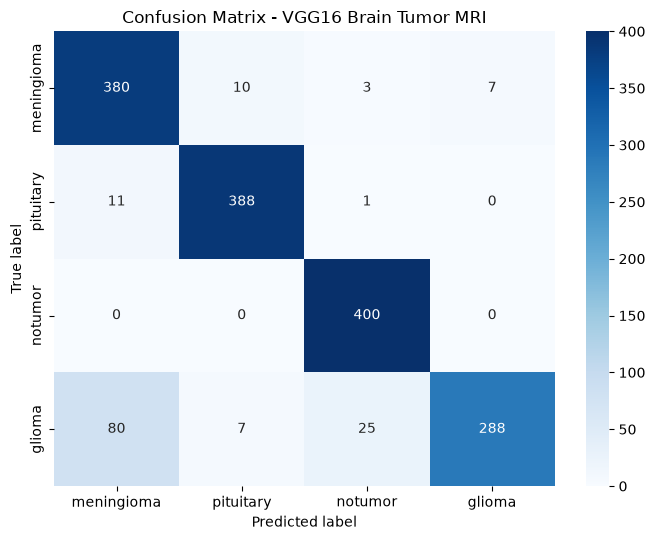

In [18]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

conf_matrix = confusion_matrix(test_labels_encoded, y_pred)
print("Confusion Matrix (rows = true, columns = predicted)")
print(conf_matrix)

plt.figure(figsize=(7, 5.5))
sns.heatmap(
    conf_matrix,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names,
)
plt.xlabel('Predicted label')
plt.ylabel('True label')
plt.title('Confusion Matrix - VGG16 Brain Tumor MRI')
plt.tight_layout()
plt.show()

## ROC Curve (One-vs-Rest)

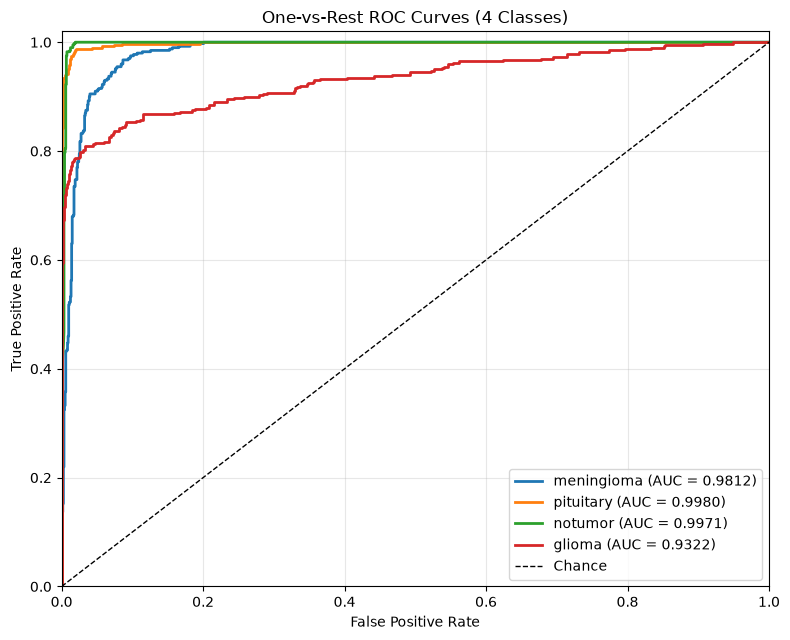

Macro-average AUC: 0.9771


In [19]:
from sklearn.metrics import roc_curve, auc

# One-vs-rest: each class as positive against the other three
num_classes = len(class_names)
y_test_onehot = label_binarize(test_labels_encoded, classes=np.arange(num_classes))

plt.figure(figsize=(8, 6.5))
for class_index, class_name in enumerate(class_names):
    fpr, tpr, _ = roc_curve(y_test_onehot[:, class_index], test_predictions[:, class_index])
    class_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, linewidth=2, label=f"{class_name} (AUC = {class_auc:.4f})")

plt.plot([0, 1], [0, 1], 'k--', linewidth=1, label='Chance')
plt.xlim(0, 1)
plt.ylim(0, 1.02)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('One-vs-Rest ROC Curves (4 Classes)')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

macro_auc = np.mean([
    auc(*roc_curve(y_test_onehot[:, i], test_predictions[:, i])[:2])
    for i in range(num_classes)
])
print(f"Macro-average AUC: {macro_auc:.4f}")